In [1]:
import hydra
from omegaconf import DictConfig
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from numpy.typing import NDArray

In [2]:
from eo_toolkit import (
    load_cached_sentinel1_as_numpy_tensor,
    compute_harmonic_baselines,
    slice_tensor_with_time_interval,
    compute_sentinel1_radar_index,
    compute_expected_baseline_and_residuals,
    compute_one_sided_cusum,
    bootstrap_cusum_paths,
)

In [4]:
darney = "sentinel1_lat_48.008_lon_6.0816_size_3000"
path_to_data = Path("../data") / darney

sentinel1_data = load_cached_sentinel1_as_numpy_tensor(path_to_data)

random_seed = 0
nb_random_cells = 4

_, _, height, width = sentinel1_data["bands"].shape
np.random.seed(random_seed)  # Fixed seed for reproducibility
random_y_positions = np.random.randint(0, height, size=nb_random_cells)
random_x_positions = np.random.randint(0, width, size=nb_random_cells)
pixel_coordinates = list(zip(random_y_positions, random_x_positions))


# Scolyte infestation started in 2018

baseline_start_date = "2014-01-01"
baseline_end_date = "2017-12-31"  

observation_start_date = "2018-01-01"
observation_end_date = "2021-12-31"

nb_harmonics = 2
cusum_slack = 0.2
cusum_percentile = 99

In [5]:
# Compute the radar index, and concatenate to the data tensor as an additional band
radar_index_tensor = compute_sentinel1_radar_index(sentinel1_data["bands"], vv_index=0, vh_index=1)
data_tensor = np.concatenate([sentinel1_data["bands"], radar_index_tensor], axis=1)

In [6]:
baseline_data_tensor, baseline_coefficients, baseline_dates, baseline_t = compute_harmonic_baselines(
    data_tensor=data_tensor,
    dates=sentinel1_data["dates"],
    start_date=baseline_start_date,
    end_date=baseline_end_date,
    nb_harmonics=nb_harmonics
)

# Shape is (bands, height, width, 5) for 2 harmonics (intercept + 2*cos + 2*sin)
print(f"Baseline coefficients shape: {baseline_coefficients.shape}")

Baseline coefficients shape: (3, 104, 105, 5)


In [3]:
def plot_random_pixel_baselines(
    data_tensor: NDArray[np.float32],
    coefficients: NDArray[np.float64],
    t_baseline: NDArray[np.float64],
    dates: NDArray[np.datetime64],
    pixel_coordinates: list[tuple[int, int]],
    band_idx: int = 0  # [vv, vh, ratio]
) -> None:
    """Plots a 2x2 grid of 4 specified pixel coordinates comparing raw baseline time series
    against the fitted harmonic model.
    """
    # Reconstruct design matrix for the baseline period to compute fitted curves
    n_coeffs = coefficients.shape[-1]
    num_harmonics = (n_coeffs - 1) // 2

    X_cols = [np.ones_like(t_baseline)]
    for k in range(1, num_harmonics + 1):
        X_cols.append(np.cos(2.0 * np.pi * k * t_baseline))
        X_cols.append(np.sin(2.0 * np.pi * k * t_baseline))
    X = np.column_stack(X_cols)
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
    axes = axes.flatten()

    for idx, (h, w) in enumerate(pixel_coordinates):
        ax = axes[idx]

        # Extract raw time series and fitted coefficients for this pixel/band
        y_raw = data_tensor[:, band_idx, h, w]
        beta = coefficients[band_idx, h, w, :]

        # Compute harmonic fit
        y_fit = X @ beta

        # Plot
        ax.plot(dates, y_raw, 'ko', markersize=3, alpha=0.5, label='Raw Data')
        ax.plot(dates, y_fit, 'r-', linewidth=2, label='Harmonic Fit')

        ax.set_title(f"Pixel [{h}, {w}]", fontsize=10)
        ax.grid(True, linestyle='--', alpha=0.5)
        if idx == 0:
            ax.legend(loc='upper right', fontsize=8)

    plt.suptitle(f"Baseline Harmonic Fits (Band {band_idx}) - 4-Pixel Sample", fontsize=14)
    plt.tight_layout()
    plt.show()

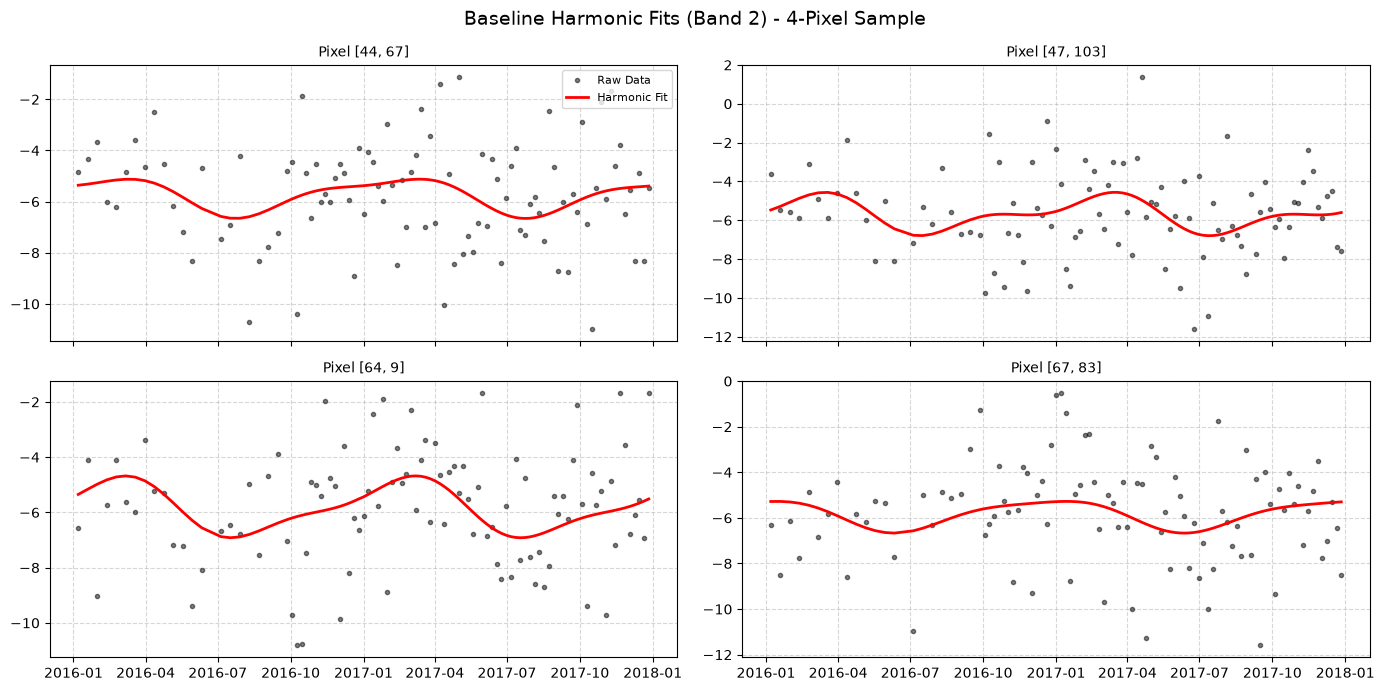

In [7]:
plot_random_pixel_baselines(
    data_tensor=baseline_data_tensor,
    coefficients=baseline_coefficients,
    t_baseline=baseline_t,
    dates=baseline_dates,
    pixel_coordinates=pixel_coordinates,
    band_idx=2
)

In [8]:
baseline_expected, residuals, monitoring_data_tensor, monitoring_dates = compute_expected_baseline_and_residuals(
    data_tensor=data_tensor,
    dates=sentinel1_data["dates"],
    coefficients=baseline_coefficients,
    start_date=observation_start_date,
    end_date=observation_end_date,
    nb_harmonics=nb_harmonics,
)

In [9]:
def plot_monitoring_and_residuals(
    monitoring_data: NDArray[np.float32],
    baseline_expected: NDArray[np.float32],
    residuals: NDArray[np.float32],
    dates: NDArray[np.datetime64],
    pixel_coordinates: list[tuple[int, int]],
    band_idx: int = 2,  # Default to band 2 (VH - VV index)
    band_name: str = "VH - VV Radar Index"
) -> None:
    """Plots a grid of specified pixel coordinates comparing the monitoring observations 
    against the expected baseline, alongside their resulting residuals.
    """
    n_samples = len(pixel_coordinates)
    
    fig, axes = plt.subplots(n_samples, 2, figsize=(14, 3 * n_samples), sharex=True)
    if n_samples == 1:
        axes = np.expand_dims(axes, axis=0)
        
    for idx, (h, w) in enumerate(pixel_coordinates):
        # Extract time series for the selected pixel
        obs = monitoring_data[:, band_idx, h, w]
        pred = baseline_expected[:, band_idx, h, w]
        res = residuals[:, band_idx, h, w]
        
        # --- Left Column: Observations vs Expected Baseline ---
        ax_ts = axes[idx, 0]
        ax_ts.plot(dates, obs, 'ko-', markersize=3, alpha=0.5, label='Observed Data')
        ax_ts.plot(dates, pred, 'r-', linewidth=2, label='Expected Baseline')
        ax_ts.set_ylabel("Backscatter / Index", fontsize=9)
        ax_ts.set_title(f"Pixel [{h}, {w}] - {band_name}", fontsize=10)
        ax_ts.grid(True, linestyle='--', alpha=0.5)
        if idx == 0:
            ax_ts.legend(loc='upper right', fontsize=8)
            
        # --- Right Column: Residuals (Deviation Magnitude) ---
        ax_res = axes[idx, 1]
        ax_res.plot(dates, res, 'b-', linewidth=1.5, label='Residual (Base - Obs)')
        ax_res.axhline(0, color='gray', linestyle='--', linewidth=1)
        ax_res.fill_between(dates, res, 0, where=(res > 0), color='salmon', alpha=0.3, label='Positive Deviation (Stress)')
        ax_res.set_ylabel("Residual Value", fontsize=9)
        ax_res.set_title(f"Pixel [{h}, {w}] - Residual Deviation", fontsize=10)
        ax_res.grid(True, linestyle='--', alpha=0.5)
        if idx == 0:
            ax_res.legend(loc='upper right', fontsize=8)

    plt.xlabel("Monitoring Date", fontsize=10)
    plt.tight_layout()
    plt.show()

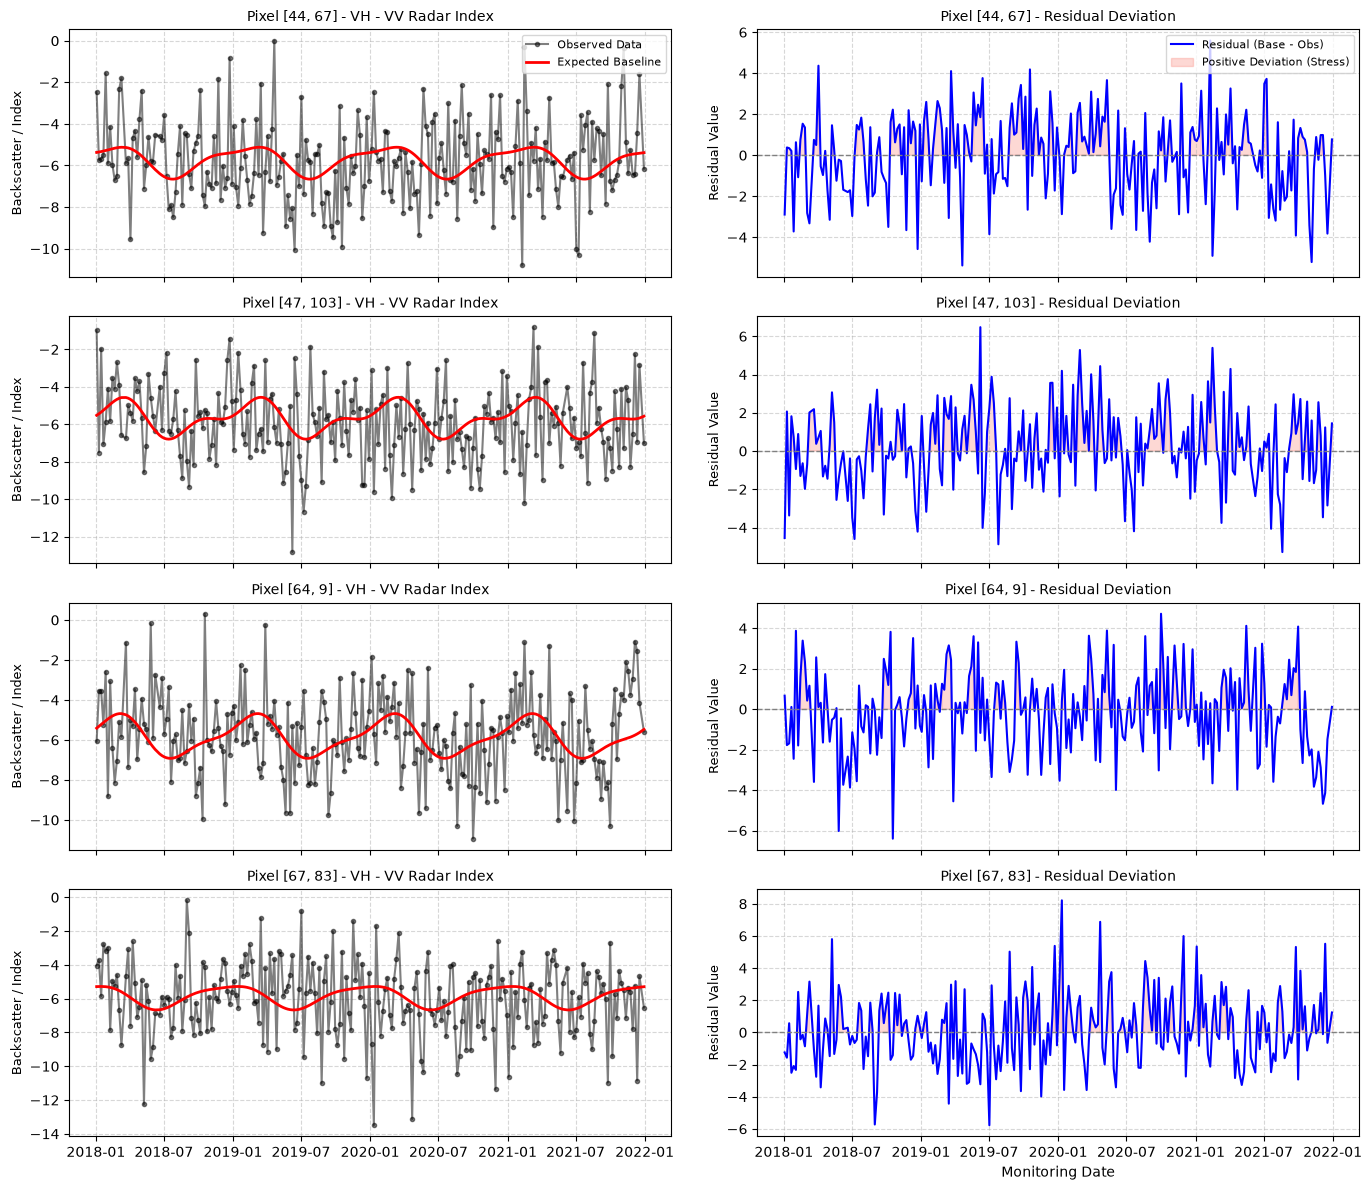

In [10]:
plot_monitoring_and_residuals(
    monitoring_data=monitoring_data_tensor,
    baseline_expected=baseline_expected,
    residuals=residuals,
    dates=monitoring_dates,
    pixel_coordinates=pixel_coordinates,
    band_idx=2,
    band_name="VH - VV Radar Index"
)

In [11]:
bootstrap_cusums = bootstrap_cusum_paths(
    data_tensor=data_tensor,
    dates=sentinel1_data["dates"],
    coefficients=baseline_coefficients,
    start_date=baseline_start_date,
    end_date=baseline_end_date,
    nb_harmonics=nb_harmonics,
    nb_bootstraps=1000,
    block_size=12,
    slack=cusum_slack,
)

In [12]:
def plot_bootstrap_cusum_envelope(
    bootstrap_cusums: NDArray[np.float32],
    dates: NDArray[np.datetime64],
    pixel_coordinates: list[tuple[int, int]],
    band_idx: int = 2,
    band_name: str = "VH - VV Radar Index"
) -> None:
    """Plots the median and confidence envelopes (percentile bands) of the 
    bootstrap CUSUM paths for the specified 4 pixels. 

    Parameters:
    - bootstrap_cusums: 5D array of shape (nb_bootstraps, time, bands, height, width).
    - dates: Array of datetimes corresponding to the baseline/time axis.
    - pixel_coordinates: List of 4 (h, w) tuples matching previous visualizations.
    - band_idx: Index of the band/feature visualized.
    - band_name: Label description of the band for plot titles.
    """
    n_bootstraps, n_time, n_bands, height, width = bootstrap_cusums.shape
    
    # Strictly 2x2 layout for the 4 consistent pixels
    fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
    axes = axes.flatten()
    
    for idx, (h, w) in enumerate(pixel_coordinates):
        ax = axes[idx]
        
        # Extract all bootstrap CUSUM trajectories for this specific pixel & band -> shape: (n_bootstraps, n_time)
        pixel_paths = bootstrap_cusums[:, :, band_idx, h, w]
        
        # Compute distribution percentiles across bootstrap samples at each time step
        p50 = np.percentile(pixel_paths, 50, axis=0)  # Median expected path
        p95 = np.percentile(pixel_paths, 95, axis=0)  # 95th percentile envelope
        p99 = np.percentile(pixel_paths, 99, axis=0)  # 99th percentile envelope
        
        # Plot confidence envelopes and median trajectory
        ax.fill_between(dates, p50, p99, color='skyblue', alpha=0.2, label='50% - 99% Noise Envelope')
        ax.fill_between(dates, p50, p95, color='dodgerblue', alpha=0.3, label='50% - 95% Noise Envelope')
        ax.plot(dates, p50, 'b-', linewidth=2, label='Median Bootstrap CUSUM')
        
        ax.set_title(f"Pixel [{h}, {w}] - {band_name}", fontsize=10)
        ax.set_ylabel("CUSUM Accumulation", fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.5)
        if idx == 0:
            ax.legend(loc='upper left', fontsize=8)

    plt.xlabel("Baseline Time Axis", fontsize=10)
    plt.suptitle("Bootstrap CUSUM Noise Envelopes (Calibration Check)", fontsize=14)
    plt.tight_layout()
    plt.show()

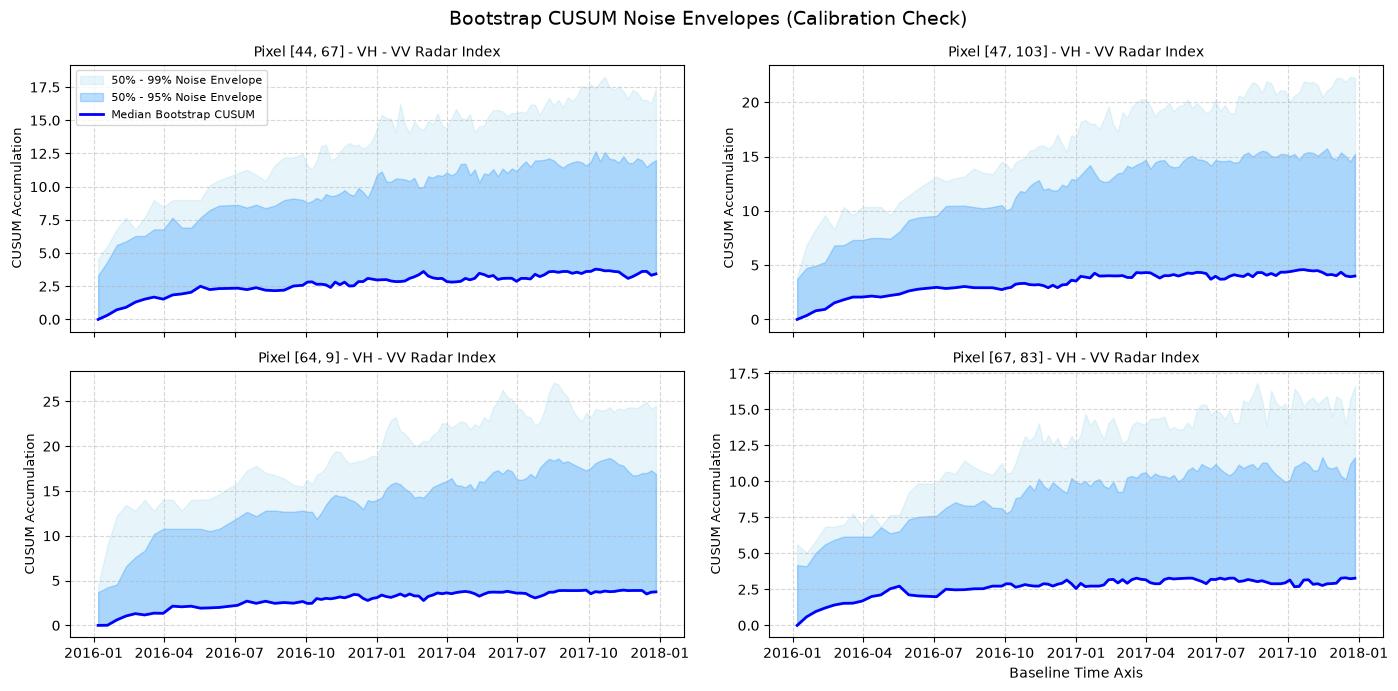

In [13]:
plot_bootstrap_cusum_envelope(
    bootstrap_cusums=bootstrap_cusums,
    dates=baseline_dates,
    pixel_coordinates=pixel_coordinates,
    band_idx=2,
    band_name="VH - VV Radar Index"
)

In [14]:
# Alarm threshold (quantile-based)
quantile = 99
max_bootstrap_peaks = np.max(bootstrap_cusums, axis=1)  # Shape: (nb_bootstraps, bands, height, width)
alarm_threshold = np.percentile(max_bootstrap_peaks, cusum_percentile, axis=0)  # Shape: (bands, height, width)

In [15]:
def plot_alarm_thresholds(
    alarm_threshold: NDArray[np.float32],
    quantile: int = 99,
    band_titles: list[str] = ["VV Band", "VH Band", "VH - VV Radar Index"]
) -> None:
    """Plots a 1x3 grid displaying the spatial CUSUM alarm threshold maps for each band.

    Parameters:
    - alarm_threshold: 3D array of shape (bands, height, width).
    - quantile: The percentile value used for threshold calculation (for title labeling).
    - band_titles: List of descriptive titles for the bands.
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for b_idx, ax in enumerate(axes):    
        threshold_map = alarm_threshold[b_idx, :, :]    
        im = ax.imshow(threshold_map, cmap='viridis', origin='upper')
        ax.set_title(f"Alarm Threshold ({quantile}th percentile) - {band_titles[b_idx]}", fontsize=10)
        ax.axis('off')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        
    plt.suptitle("CUSUM alarm thresholds", fontsize=14)
    plt.tight_layout()
    plt.show()

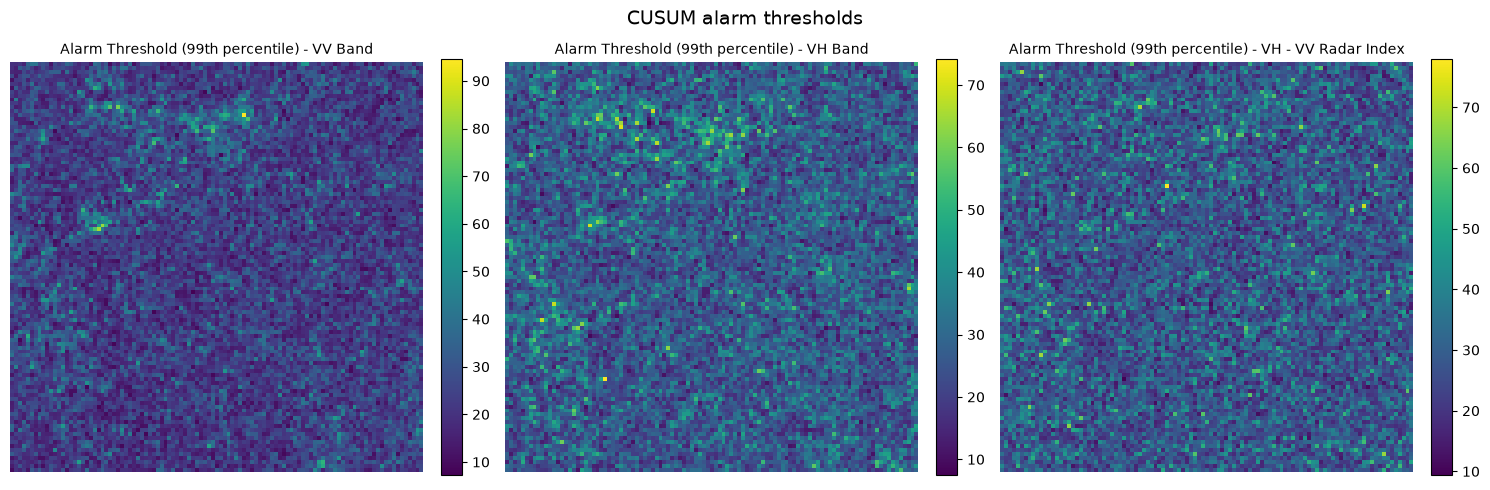

In [16]:
plot_alarm_thresholds(alarm_threshold, cusum_percentile)

In [17]:
# Evaluate on the monitoring period
_, monitoring_residuals, monitoring_tensor, monitoring_dates = compute_expected_baseline_and_residuals(
    data_tensor=data_tensor,
    dates=sentinel1_data["dates"],
    coefficients=baseline_coefficients,
    start_date=observation_start_date,
    end_date=observation_end_date,
    nb_harmonics=nb_harmonics
)

# Run CUSUM on the monitoring observations
monitoring_cusum = compute_one_sided_cusum(monitoring_residuals, slack=cusum_slack)

# Anomaly detection: If the CUSUM surpasses the bootstrap-derived threshold
alerts = monitoring_cusum > alarm_threshold  # (time, bands, H, W)

In [18]:
def plot_anomaly_summary(
    alerts: NDArray[np.bool_],
    dates: NDArray[np.datetime64],
    band_titles: list[str] = ["VV Band", "VH Band", "VH - VV Radar Index"]
) -> None:
    """Plots a 2x3 summary grid of CUSUM anomaly detection results:
    - Top Row: Spatial count maps showing total anomaly persistence per pixel over time.
    - Bottom Row: Global temporal time series showing total active anomaly counts per date.

    Parameters:
    - alerts: Boolean 4D tensor of shape (time, bands, height, width) indicating active alarms.
    - dates: Array of datetimes corresponding to the monitoring timeline.
    - band_titles: Titles for the 3 radar channels/indices.
    """
    n_time, n_bands, height, width = alerts.shape

    # 1st Line Calculations: Total spatial count per pixel (collapse time axis)
    spatial_counts = np.sum(alerts, axis=0)  # Shape: (bands, height, width)

    # 2nd Line Calculations: Global count per time step (collapse spatial axes)
    temporal_counts = np.sum(alerts, axis=(2, 3))  # Shape: (time, bands)

    # Create 2x3 subplot grid
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))

    for b_idx in range(n_bands):
        # --- Row 1: Spatial Map ---
        ax_spatial = axes[0, b_idx]
        im = ax_spatial.imshow(spatial_counts[b_idx], cmap='YlOrRd', origin='upper')
        ax_spatial.set_title(f"Spatial Persistence - {band_titles[b_idx]}", fontsize=10)
        ax_spatial.axis('off')
        fig.colorbar(im, ax=ax_spatial, fraction=0.046, pad=0.04)

        # --- Row 2: Temporal Time Series ---
        ax_temporal = axes[1, b_idx]
        ax_temporal.plot(dates, temporal_counts[:, b_idx], color='crimson', linewidth=1.5, label='Active Anomalies')
        ax_temporal.set_title(f"Global Timeline - {band_titles[b_idx]}", fontsize=10)
        ax_temporal.set_ylabel("Global Pixel Count", fontsize=9)
        ax_temporal.set_xlabel("Monitoring Date", fontsize=9)
        ax_temporal.grid(True, linestyle='--', alpha=0.5)
        ax_temporal.tick_params(axis='x', rotation=15)

    plt.suptitle("CUSUM Forest Health Monitoring - Anomaly Summary", fontsize=14)
    plt.tight_layout()
    plt.show()

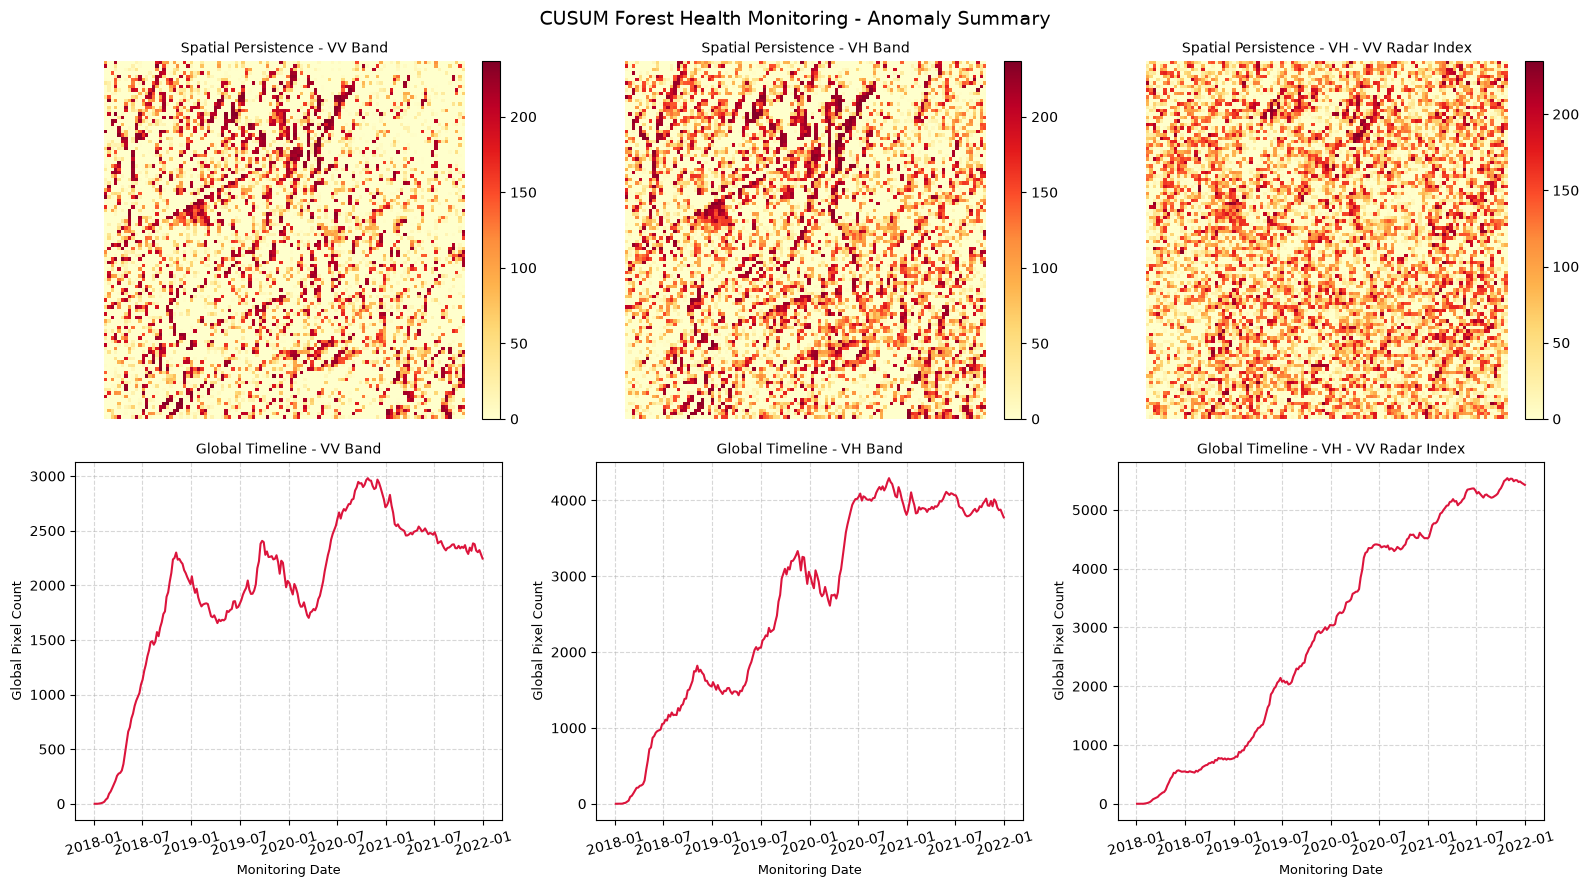

In [19]:
plot_anomaly_summary(alerts=alerts, dates=monitoring_dates)

In [20]:
def plot_pixel_cusum_trajectories(
    monitoring_cusum: NDArray[np.float32],
    alarm_threshold: NDArray[np.float32],
    dates: NDArray[np.datetime64],
    pixel_coordinates: list[tuple[int, int]],
    band_idx: int = 2,
    band_name: str = "VH - VV Radar Index"
) -> None:
    """Plots the CUSUM accumulation path against the pixel-specific alarm threshold
    for the 4 selected pixel coordinates, highlighting active anomaly triggers over time.

    Parameters:
    - monitoring_cusum: 4D array of shape (time, bands, height, width).
    - alarm_threshold: 3D array of shape (bands, height, width) containing spatial limits.
    - dates: Array of datetimes corresponding to the monitoring timeline.
    - pixel_coordinates: List of 4 (h, w) tuples matching your consistent sample.
    - band_idx: Index of the band/feature to visualize.
    - band_name: Label description of the band for plot titles.
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
    axes = axes.flatten()

    for idx, (h, w) in enumerate(pixel_coordinates):
        ax = axes[idx]

        # Extract CUSUM trajectory and specific threshold for this pixel/band
        cusum_path = monitoring_cusum[:, band_idx, h, w]
        threshold_val = alarm_threshold[band_idx, h, w]

        # Identify active alarms for this pixel
        pixel_alerts = cusum_path > threshold_val

        # Plot CUSUM trajectory
        ax.plot(dates, cusum_path, color='dodgerblue', linewidth=1.5, label='CUSUM Path')
        
        # Plot static spatial threshold boundary line
        ax.axhline(threshold_val, color='crimson', linestyle='--', linewidth=1.5, label=f'Threshold ({threshold_val:.2f})')

        # Highlight data points where alarms are active
        if np.any(pixel_alerts):
            ax.plot(dates[pixel_alerts], cusum_path[pixel_alerts], 'ro', markersize=5, label='Alarm Triggered')

        ax.set_title(f"Pixel [{h}, {w}] - {band_name}", fontsize=10)
        ax.set_ylabel("CUSUM Accumulation", fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.5)
        if idx == 0:
            ax.legend(loc='upper left', fontsize=8)

    plt.xlabel("Monitoring Date", fontsize=10)
    plt.suptitle(f"Pixel-Level CUSUM Trajectories & Alarm Triggers ({band_name})", fontsize=14)
    plt.tight_layout()
    plt.show()

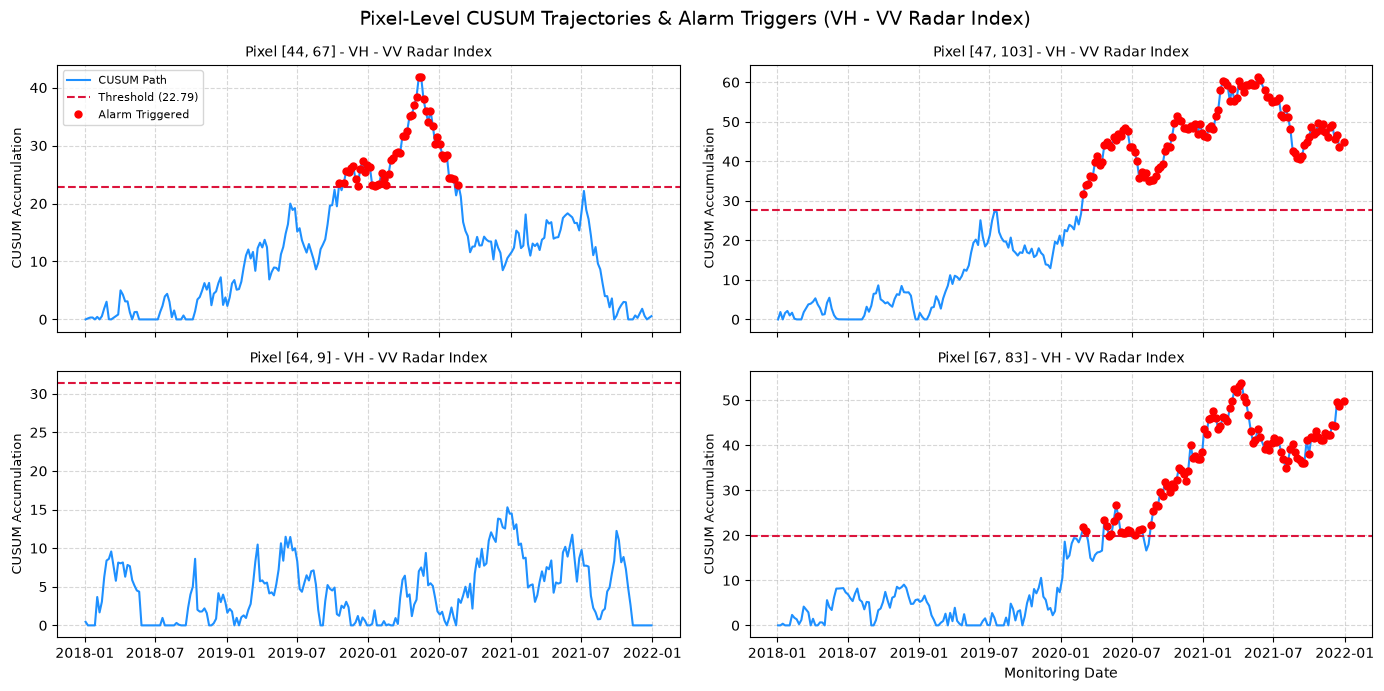

In [21]:
plot_pixel_cusum_trajectories(
    monitoring_cusum=monitoring_cusum,
    alarm_threshold=alarm_threshold,
    dates=monitoring_dates,
    pixel_coordinates=pixel_coordinates,
    band_idx=2,
    band_name="VH - VV Radar Index"
)